In [1]:
import tensorflow as tf
print("Доступные GPU:", tf.config.list_physical_devices('GPU'))

Доступные GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from tensorflow import keras

In [4]:
print(keras.__version__)

3.13.2


In [5]:
import os
import numpy as np
import keras
from keras import layers
from tensorflow import data as tf_data
import matplotlib.pyplot as plt


In [6]:
import urllib.request

In [7]:
url = "https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip"
filename = "kagglecatsanddogs_5340.zip"

In [9]:
urllib.request.urlretrieve(url, filename)

('kagglecatsanddogs_5340.zip', <http.client.HTTPMessage at 0x79bf5a5b88a0>)

In [10]:
!unzip -q kagglecatsanddogs_5340.zip
!ls

 CDLA-Permissive-2.0.pdf      PetImages        sample_data
 kagglecatsanddogs_5340.zip  'readme[1].txt'


In [11]:
!ls PetImages

Cat  Dog


In [12]:
num_skipped = 0
for folder_name in ("Cat", "Dog"):
    folder_path = os.path.join("PetImages", folder_name)
    for fname in os.listdir(folder_path):
        fpath = os.path.join(folder_path, fname)
        try:
            fobj = open(fpath, "rb")
            is_jfif = b"JFIF" in fobj.peek(10)
        finally:
            fobj.close()

        if not is_jfif:
            num_skipped += 1
            # Delete corrupted image
            os.remove(fpath)

print(f"Deleted {num_skipped} images.")


Deleted 1590 images.


In [13]:
image_size = (180, 180)
batch_size = 128

train_ds, val_ds = keras.utils.image_dataset_from_directory(
    "PetImages",
    validation_split=0.2,
    subset="both",
    seed=1337,
    image_size=image_size,
    batch_size=batch_size,
)


Found 23410 files belonging to 2 classes.
Using 18728 files for training.
Using 4682 files for validation.


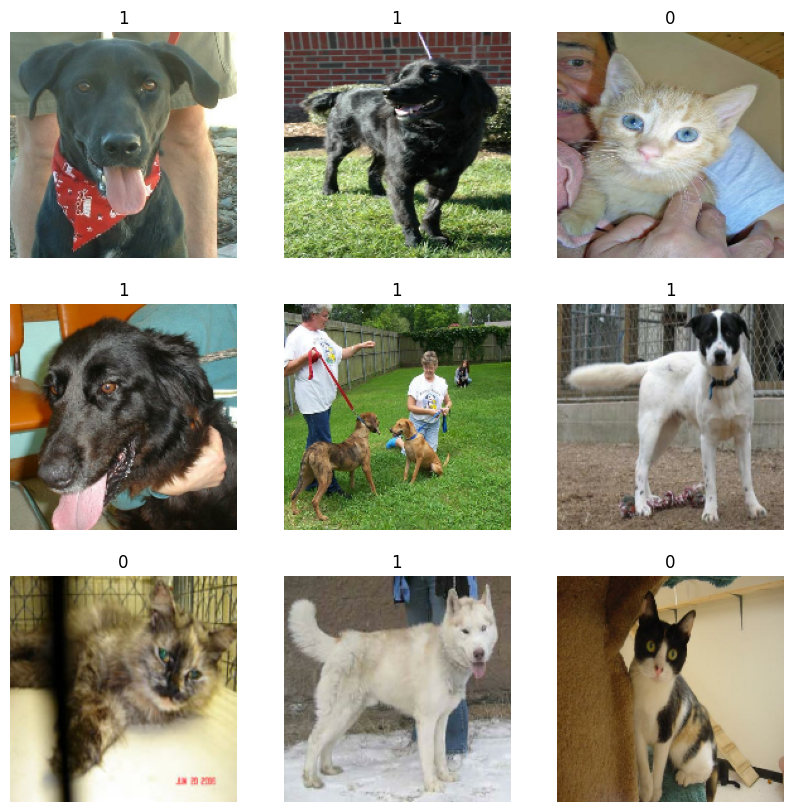

In [14]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(np.array(images[i]).astype("uint8"))
        plt.title(int(labels[i]))
        plt.axis("off")


In [15]:
data_augmentation_layers = [
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
]


def data_augmentation(images):
    for layer in data_augmentation_layers:
        images = layer(images)
    return images


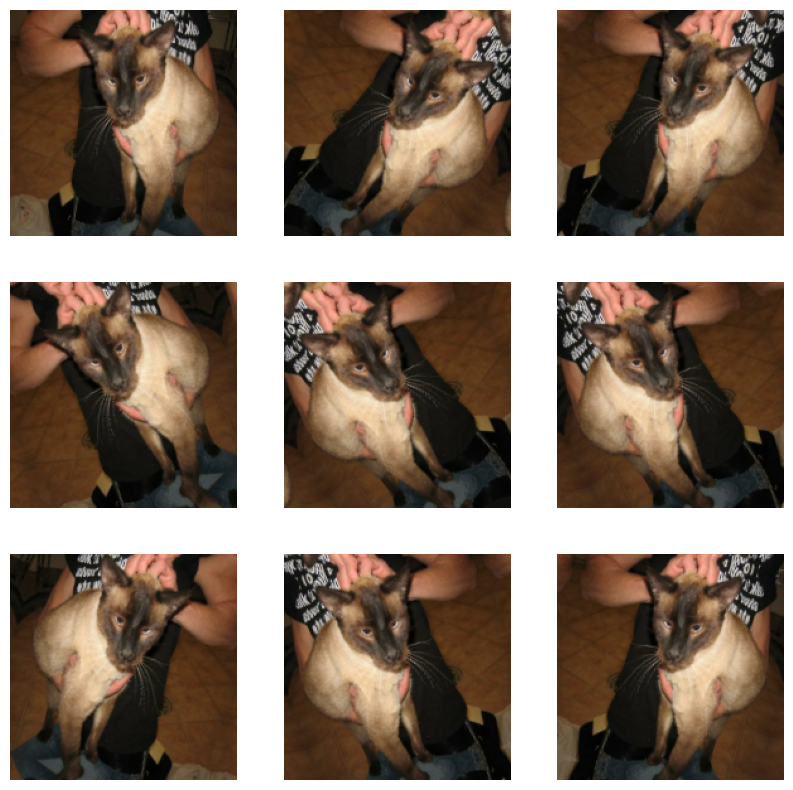

In [16]:
plt.figure(figsize=(10, 10))
for images, _ in train_ds.take(1):
    for i in range(9):
        augmented_images = data_augmentation(images)
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(np.array(augmented_images[0]).astype("uint8"))
        plt.axis("off")


In [17]:
augmented_train_ds = train_ds.map(lambda x, y: (data_augmentation(x), y))

In [18]:
# Apply `data_augmentation` to the training images.
train_ds = train_ds.map(
    lambda img, label: (data_augmentation(img), label),
    num_parallel_calls=tf_data.AUTOTUNE,
)
# Prefetching samples in GPU memory helps maximize GPU utilization.
train_ds = train_ds.prefetch(tf_data.AUTOTUNE)
val_ds = val_ds.prefetch(tf_data.AUTOTUNE)




In [19]:
def make_model(input_shape, num_classes):
    inputs = keras.Input(shape=input_shape)

    # Entry block
    x = layers.Rescaling(1.0 / 255)(inputs)
    x = layers.Conv2D(128, 3, strides=2, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    previous_block_activation = x  # Set aside residual

    for size in [256, 512, 728]:
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)

        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)

        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

        # Project residual
        residual = layers.Conv2D(size, 1, strides=2, padding="same")(
            previous_block_activation
        )
        x = layers.add([x, residual])  # Add back residual
        previous_block_activation = x  # Set aside next residual

    x = layers.SeparableConv2D(1024, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.GlobalAveragePooling2D()(x)
    if num_classes == 2:
        units = 1
    else:
        units = num_classes

    x = layers.Dropout(0.25)(x)
    # We specify activation=None so as to return logits
    outputs = layers.Dense(units, activation=None)(x)
    return keras.Model(inputs, outputs)


model = make_model(input_shape=image_size + (3,), num_classes=2)
keras.utils.plot_model(model, show_shapes=True)


In [20]:
%pip install pydot

In [21]:
%pip install graphviz

In [22]:
epochs = 10

callbacks = [
    keras.callbacks.ModelCheckpoint("save_at_{epoch}.keras"),
]
model.compile(
    optimizer=keras.optimizers.Adam(3e-4),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[keras.metrics.BinaryAccuracy(name="acc")],
)
model.fit(
    train_ds,
    epochs=epochs,
    callbacks=callbacks,
    validation_data=val_ds,
)


Epoch 1/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 433s 2s/step - acc: 0.6747 - loss: 0.5879 - val_acc: 0.4957 - val_loss: 0.6932
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 185s 1s/step - acc: 0.7718 - loss: 0.4578 - val_acc: 0.4957 - val_loss: 0.7074
Epoch 3/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 186s 1s/step - acc: 0.8271 - loss: 0.3714 - val_acc: 0.5478 - val_loss: 0.7228
Epoch 4/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 187s 1s/step - acc: 0.8594 - loss: 0.3084 - val_acc: 0.4957 - val_loss: 0.8513
Epoch 5/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 185s 1s/step - acc: 0.8853 - loss: 0.2645 - val_acc: 0.5820 - val_loss: 0.7450
Epoch 6/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 186s 1s/step - acc: 0.8948 - loss: 0.2371 - val_acc: 0.9009 - val_loss: 0.2645
Epoch 7/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 186s 1s/step - acc: 0.9111 - loss: 0.2092 - val_acc: 0.6544 - val_loss: 0.8001
Epoch 8/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 186s 1s/step - acc: 0.9210 - loss: 0.1853 - val_acc: 0.7777 - val_loss: 0.4821
Epoch 9/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 186s 1s/

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
This image is 60.96% cat and 39.04% dog.


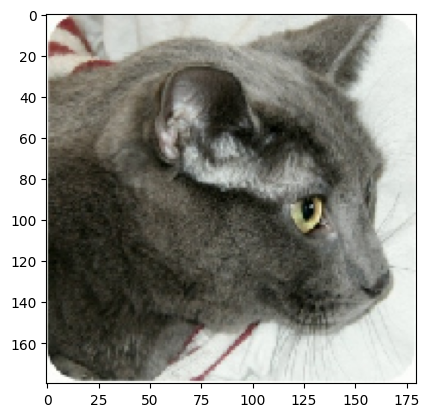

In [23]:
img = keras.utils.load_img("PetImages/Cat/6779.jpg", target_size=image_size)
plt.imshow(img)

img_array = keras.utils.img_to_array(img)
img_array = keras.ops.expand_dims(img_array, 0)  # Create batch axis

predictions = model.predict(img_array)
score = float(keras.ops.sigmoid(predictions[0][0]))
print(f"This image is {100 * (1 - score):.2f}% cat and {100 * score:.2f}% dog.")


In [24]:
model.save("KERAS.keras")